[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/grabuffo/brain-modeling-course/blob/main/notebooks/D1_C0_NB00b_equations_primer.ipynb)

# Day 1 · Chapter 0 · Notebook 00b — Equations of change: derivatives, differential equations, and how a computer solves them

**Goal.** Every model in this course is written as a **differential equation**: a rule that says how fast some quantity
(a membrane voltage, a firing rate, a phase) *changes*, given its current value. This notebook is a gentle refresher for
those who are not familiar or have not used them for a while. By the end you will be able to read an equation like

$$\frac{dv}{dt} = -\frac{v - E_L}{\tau} + \frac{R\,I(t)}{\tau}$$

and to write the five lines of code that solve it. Nothing else in the course requires more mathematics than this.

In [1]:
# --- Setup (run once) -------------------------------------------------------
# On Google Colab this downloads the course code; on your laptop it does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("brain-modeling-course"):
    !git clone -q https://github.com/grabuffo/brain-modeling-course.git
    %cd brain-modeling-course/notebooks
    !pip -q install numba ipywidgets
sys.path.insert(0, os.path.abspath(".."))   # so that `import src` works

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
from src import plotting
from src.plotting import slider
plotting.setup()
DATA = '../data/data_tour'

## 1. A derivative is a rate of change

If $v(t)$ is the membrane voltage at time $t$, its **derivative** $\frac{dv}{dt}$ (also written $\dot v$) is how fast it
changes: millivolts per millisecond. With data sampled every $\Delta t$, we estimate it as

$$\frac{dv}{dt}(t) \approx \frac{v(t+\Delta t) - v(t)}{\Delta t}.$$

The smaller $\Delta t$, the better the estimate. Let us compute it on the human neuron of NB00 (sampled every 0.1 ms):

fastest rise during a spike: 298 mV/ms;  while slowly charging between spikes: ~0.31 mV/ms


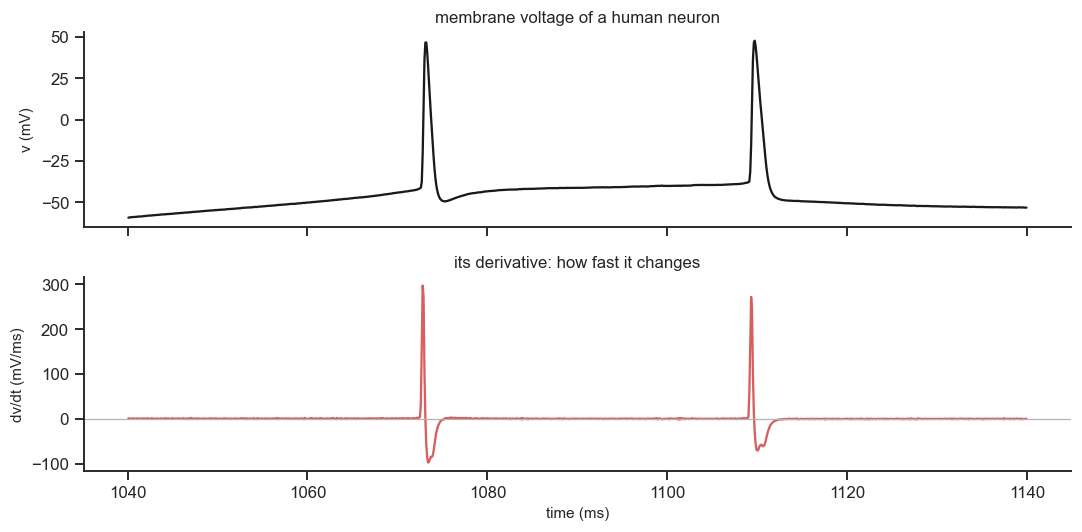

In [2]:
cell = np.load(f"{DATA}/human_neuron_allen_531523484.npz")
t_ms = cell["t"] * 1e3                         # time in ms
v = cell["V"][25]                              # one current step that makes the neuron fire
dt_data = t_ms[1] - t_ms[0]
dvdt = (v[1:] - v[:-1]) / dt_data              # finite difference: (v(t+dt) - v(t)) / dt   [mV/ms]

sel = (t_ms > 1040) & (t_ms < 1140)
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(t_ms[sel], v[sel], "k"); ax[0].set(ylabel="v (mV)", title="membrane voltage of a human neuron")
ax[1].plot(t_ms[:-1][sel[:-1]], dvdt[sel[:-1]], "C3"); ax[1].axhline(0, c="0.7", lw=0.8)
ax[1].set(xlabel="time (ms)", ylabel="dv/dt (mV/ms)", title="its derivative: how fast it changes")
plt.tight_layout()
print(f"fastest rise during a spike: {dvdt.max():.0f} mV/ms;  while slowly charging between spikes: ~{np.median(dvdt[sel[:-1]]):.2f} mV/ms")

* Where $v$ rises, $\frac{dv}{dt}>0$; where it falls, $\frac{dv}{dt}<0$; at a peak or a flat stretch, $\frac{dv}{dt}=0$.
* During a spike the voltage changes hundreds of times faster than between spikes. This is why spiking models need small
  time steps.

## 2. A differential equation is a rule for the change

Data give us $v(t)$, and from it $\frac{dv}{dt}$. A **model** goes the other way: it states a rule for $\frac{dv}{dt}$
as a function of the current state, and from the rule we compute $v(t)$.

**Example: the passive membrane.** Below threshold, a neuron behaves like an RC circuit: a capacitor (the membrane) in
parallel with a resistor (the leak channels). Current that enters charges the capacitor; the leak pulls the voltage back
to rest:

$$\tau\,\frac{dv}{dt} = -\big(v - E_L\big) + R\,I(t)$$

| symbol | meaning | value here |
|---|---|---|
| $v$ | membrane voltage (the **state variable**) | mV |
| $E_L$ | resting (leak reversal) potential | −70 mV |
| $\tau = RC$ | membrane time constant | 10 ms |
| $R$ | membrane resistance | 100 MΩ |
| $I(t)$ | injected current (the **input**) | 0.15 nA (= 150 pA) |

Read it as a sentence: *the voltage changes in proportion to how far it is from rest (pulled back), plus a push from the
input.* If $v$ is above $E_L$ (and $I=0$), $\frac{dv}{dt}<0$ and $v$ goes down; if below, it goes up.

## 3. Solving it on a computer: Euler's method

Turn the definition of the derivative around. If we know $v$ at time $t$, the rule tells us the slope, and we take a
small step along it:

$$v(t+\Delta t) \approx v(t) + \Delta t\cdot\frac{dv}{dt}\Big|_t = v(t) + \frac{\Delta t}{\tau}\Big[-(v(t)-E_L) + R\,I(t)\Big].$$

Starting from a known **initial condition** $v(0)$ we repeat this step: $v(0)\to v(\Delta t)\to v(2\Delta t)\to\dots$
This is **Euler's method**, and it is all a simulator does (with more equations, and sometimes a cleverer step).

In [3]:
tau, E_L, R = 10.0, -70.0, 100.0           # ms, mV, MOhm   (MOhm x nA = mV)
I0 = 0.15                                  # nA

def f(v, I):                               # the rule: dv/dt as a function of the state and the input
    return (-(v - E_L) + R * I) / tau

dt = 0.5                                   # ms
T = 100.0
n = int(T / dt)
t = np.arange(n) * dt
I = np.where((t >= 20) & (t < 70), I0, 0.0)  # a current step from 20 to 70 ms
v = np.empty(n)
v[0] = E_L                                 # initial condition: at rest
for k in range(n - 1):
    v[k + 1] = v[k] + dt * f(v[k], I[k])   # Euler step

print(" step   t (ms)   v (mV)   dv/dt (mV/ms)")
for k in [39, 40, 41, 42, 43]:
    print(f"{k:5d} {t[k]:8.1f} {v[k]:8.2f} {f(v[k], I[k]):10.2f}")

 step   t (ms)   v (mV)   dv/dt (mV/ms)
   39     19.5   -70.00       0.00
   40     20.0   -70.00       1.50
   41     20.5   -69.25       1.43
   42     21.0   -68.54       1.35
   43     21.5   -67.86       1.29


For a linear equation like this one we also know the **exact** solution: during the step the voltage approaches
$E_L + RI_0$ exponentially, $v(t) = E_L + RI_0\,(1-e^{-(t-20)/\tau})$, and after the step it decays back. Compare:

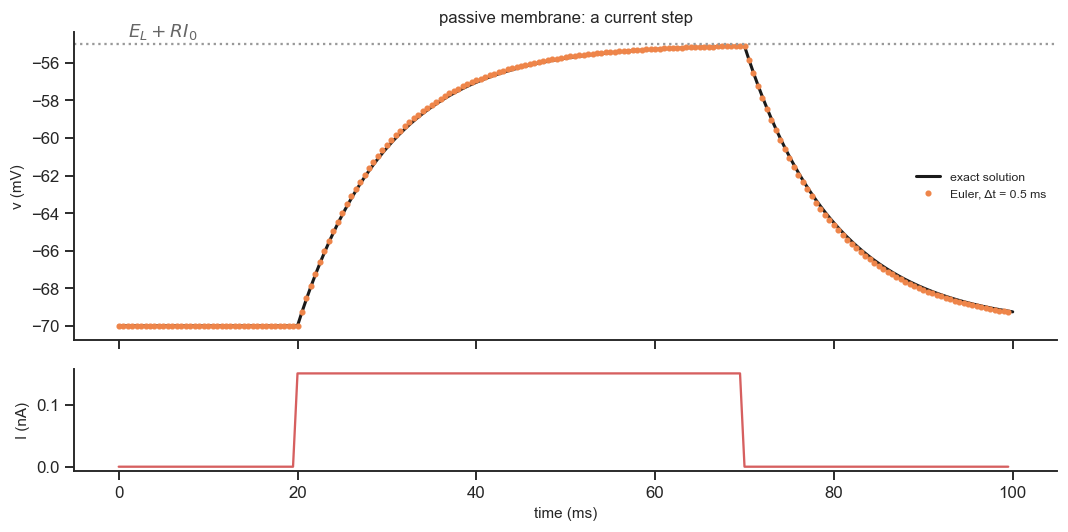

In [4]:
def exact(t):
    v = np.full_like(t, E_L)
    on = (t >= 20) & (t < 70)
    v[on] = E_L + R * I0 * (1 - np.exp(-(t[on] - 20) / tau))
    v_end = E_L + R * I0 * (1 - np.exp(-50 / tau))
    off = t >= 70
    v[off] = E_L + (v_end - E_L) * np.exp(-(t[off] - 70) / tau)
    return v

tf = np.linspace(0, T, 2001)
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))
ax[0].plot(tf, exact(tf), "k", lw=2, label="exact solution")
ax[0].plot(t, v, "o", c="C1", ms=3, label=f"Euler, Δt = {dt} ms")
ax[0].axhline(E_L + R * I0, c="0.6", ls=":"); ax[0].text(1, E_L + R * I0 + 0.4, "$E_L + R I_0$", color="0.4")
ax[0].set(ylabel="v (mV)", title="passive membrane: a current step"); ax[0].legend(fontsize=8)
ax[1].plot(t, I, "C3"); ax[1].set(xlabel="time (ms)", ylabel="I (nA)")
plt.tight_layout()

## 4. How small should Δt be?

Euler's method assumes the slope stays constant during one step. This is a good approximation only if the step is short
compared with how fast things change (here, $\tau=10$ ms). Two things can go wrong:

* **inaccuracy**: the error grows with $\Delta t$ (for Euler, roughly in proportion to $\Delta t$);
* **instability**: if $\Delta t > 2\tau$ each step overshoots more than the last and the solution explodes.

### Explore: the time step

In [5]:
def euler_membrane(dt, T=100.0):
    n = int(T / dt) + 1
    t = np.arange(n) * dt
    I = np.where((t >= 20) & (t < 70), I0, 0.0)
    v = np.empty(n); v[0] = E_L
    for k in range(n - 1):
        v[k + 1] = v[k] + dt * f(v[k], I[k])
    return t, v

@interact(dt=slider(1.0, 0.1, 25.0, 0.1, "Δt (ms)"))
def explore_dt(dt):
    t, v = euler_membrane(dt)
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(tf, exact(tf), "k", lw=2, label="exact")
    ax.plot(t, v, "o-", c="C1", ms=4, lw=1, label=f"Euler, Δt = {dt} ms")
    err = np.max(np.abs(v - exact(t)))
    ax.set(xlabel="time (ms)", ylabel="v (mV)", ylim=(-90, -40), title=f"max error {err:.2f} mV" + ("   — UNSTABLE (Δt > 2τ)" if dt > 2 * tau else ""))
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='Δt (ms)', layout=Layout(wid…

* Try $\Delta t = 0.1, 1, 5, 10, 15, 21$ ms. When do the dots stop following the curve? When does it blow up?
* Rule of thumb: $\Delta t$ should be **much smaller than the fastest time scale** in the model. For spikes (~1 ms) this
  means $\Delta t \approx 0.01$–$0.1$ ms, as in NB01.

## 5. A better step: Heun's method (homework read)

Euler uses the slope at the beginning of the step. **Heun's method** (a second-order Runge–Kutta method) first takes a
trial Euler step, computes the slope there too, and then uses the **average** of the two slopes:

$$\tilde v = v(t) + \Delta t\,f\big(v(t)\big),\qquad v(t+\Delta t) = v(t) + \frac{\Delta t}{2}\Big[f\big(v(t)\big) + f\big(\tilde v\big)\Big].$$

Twice the work per step, but the error shrinks like $\Delta t^2$ instead of $\Delta t$. Most simulators in this course use
Heun (look at `src/meanfield.py`).

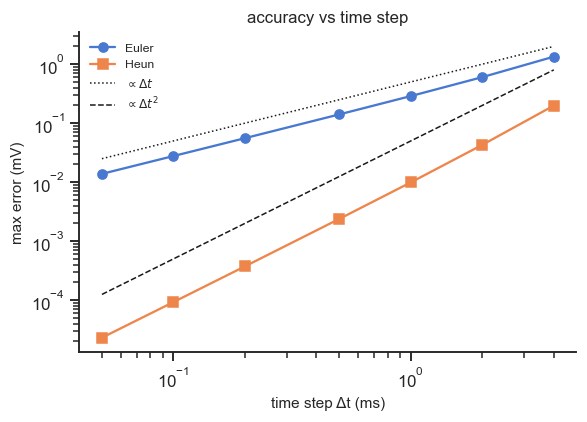

In [6]:
def heun_membrane(dt, T=100.0):
    n = int(T / dt) + 1
    t = np.arange(n) * dt
    I = np.where((t >= 20) & (t < 70), I0, 0.0)
    v = np.empty(n); v[0] = E_L
    for k in range(n - 1):
        v_trial = v[k] + dt * f(v[k], I[k])                          # predictor (an Euler step)
        v[k + 1] = v[k] + 0.5 * dt * (f(v[k], I[k]) + f(v_trial, I[k]))       # corrector (average slope; input held fixed during the step)
    return t, v

dts = np.array([0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 4.0])
err_e, err_h = [], []
for d in dts:
    t1, v1 = euler_membrane(d); err_e.append(np.max(np.abs(v1 - exact(t1))[(t1 > 25) & (t1 < 65)]))
    t2, v2 = heun_membrane(d); err_h.append(np.max(np.abs(v2 - exact(t2))[(t2 > 25) & (t2 < 65)]))
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.loglog(dts, err_e, "o-", label="Euler"); ax.loglog(dts, err_h, "s-", label="Heun")
ax.loglog(dts, 0.5 * dts, "k:", lw=1, label=r"$\propto \Delta t$"); ax.loglog(dts, 0.05 * dts**2, "k--", lw=1, label=r"$\propto \Delta t^2$")
ax.set(xlabel="time step Δt (ms)", ylabel="max error (mV)", title="accuracy vs time step"); ax.legend(fontsize=8)
plt.tight_layout()

Halve the step: Euler's error halves, Heun's error drops by four. For the same accuracy Heun can use much larger steps.
(Libraries such as `scipy.integrate.solve_ivp` use even higher-order methods with automatic step size; in this course we
write the steps out so you can see them.)

## 6. More than one variable: state space

Most models have several variables that change together. A classic engineering example, a mass on a spring with friction:
position $x$ and velocity $y$,

$$\frac{dx}{dt} = y, \qquad \frac{dy}{dt} = -k\,x - c\,y.$$

Euler works the same way, one step for each variable using the *current* values of both. Plotting $y$ against $x$ instead
of against time gives the **state space** (or **phase plane**): each point is a state, the arrows show where the rule pushes
it, and a solution is a curve following the arrows. We will use this picture constantly (NB01, NB02, NB05, NB07).

In [7]:
def spring(c, k=1.0, x0=1.0, y0=0.0, dt=0.01, T=40.0):
    n = int(T / dt); x = np.empty(n); y = np.empty(n); x[0], y[0] = x0, y0
    for i in range(n - 1):
        x[i + 1] = x[i] + dt * y[i]
        y[i + 1] = y[i] + dt * (-k * x[i] - c * y[i])
    return np.arange(n) * dt, x, y

@interact(c=slider(0.3, 0.0, 3.0, 0.05, "friction c"), k=slider(1.0, 0.2, 4.0, 0.1, "stiffness k"))
def explore_spring(c, k):
    t, x, y = spring(c, k)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(t, x, label="position x"); ax[0].plot(t, y, label="velocity y"); ax[0].legend(fontsize=8)
    ax[0].set(xlabel="time", title="time series")
    X, Y = np.meshgrid(np.linspace(-1.5, 1.5, 15), np.linspace(-1.5, 1.5, 15))
    ax[1].quiver(X, Y, Y, -k * X - c * Y, color="0.7", angles="xy")
    ax[1].plot(x, y, "C3", lw=1.5); ax[1].plot(x[0], y[0], "C3o"); ax[1].plot(0, 0, "k*", ms=10)
    ax[1].set(xlabel="x", ylabel="y", xlim=(-1.5, 1.5), ylim=(-1.5, 1.5), aspect="equal", title="state space (phase plane)")
    plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=0.3, continuous_update=False, description='friction c', layout=Layout(…

* With friction the trajectory spirals into the point $(0,0)$: a **stable fixed point** (the rule says "no change" there and
  pulls nearby states towards it). Without friction ($c=0$) it circles forever. (With Euler and $c=0$ it actually spirals
  slowly *outwards*: another face of numerical error. Try it.)
* Large friction: no oscillation, the mass creeps back. The *type* of behaviour changes with a parameter: this is the
  seed of the bifurcations of NB07.

## 7. Fixed points and their stability (one variable)

A **fixed point** $v^*$ is a state where the rule says "no change": $f(v^*)=0$. It is **stable** if nearby states move
towards it ($f$ goes from positive to negative across $v^*$) and **unstable** if they move away. For one variable we can see
it at once by plotting $\frac{dv}{dt}=f(v)$ against $v$: arrows to the right where $f>0$, to the left where $f<0$.

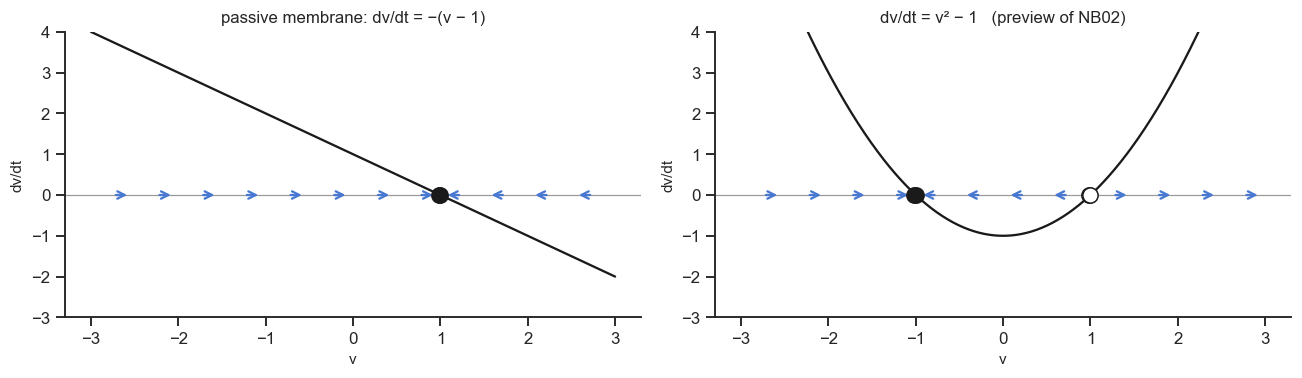

In [8]:
vv = np.linspace(-3, 3, 400)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a_, (fun, title) in zip(ax, [(lambda v: -(v - 1.0), "passive membrane: dv/dt = −(v − 1)"),
                                 (lambda v: v**2 - 1.0, "dv/dt = v² − 1   (preview of NB02)")]):
    fv = fun(vv)
    a_.plot(vv, fv, "k"); a_.axhline(0, c="0.6", lw=0.8)
    for x0 in np.linspace(-2.75, 2.75, 12):
        s = np.sign(fun(x0))
        if s != 0: a_.annotate("", xy=(x0 + 0.2 * s, 0), xytext=(x0, 0), arrowprops=dict(arrowstyle="->", color="C0", lw=1.5))
    roots = vv[np.where(np.diff(np.sign(fv)))[0]]
    for r in roots:
        slope = (fun(r + 1e-3) - fun(r - 1e-3)) / 2e-3
        a_.plot(r, 0, "o", ms=10, mfc="k" if slope < 0 else "w", mec="k", zorder=5)
    a_.set(xlabel="v", ylabel="dv/dt", title=title, ylim=(-3, 4))
plt.tight_layout()

Filled dots: stable fixed points (arrows point in). Open dots: unstable (arrows point out). On the right, a threshold: start
left of the open dot and you return to rest; start right of it and $v$ runs away — a spike. This is the QIF neuron of NB02.

## 8. Adding noise

Real neurons receive irregular input. We model it by adding a random kick at every step. The rule becomes a *stochastic*
differential equation, and the Euler step (called **Euler–Maruyama**) is

$$v(t+\Delta t) = v(t) + \Delta t\, f\big(v(t)\big) + \sigma\sqrt{\Delta t}\;\xi_t, \qquad \xi_t \sim \mathcal N(0,1)\ \text{independent at each step.}$$

Why $\sqrt{\Delta t}$ and not $\Delta t$? Independent kicks add up like a random walk: their variance grows linearly with
time, so each kick must have variance $\propto \Delta t$, i.e. size $\propto\sqrt{\Delta t}$. This makes the result
independent of the step size.

In [9]:
@interact(sigma=slider(1.0, 0.0, 4.0, 0.1, "noise σ (mV/√ms)"), dt=slider(0.1, 0.01, 1.0, 0.01, "Δt (ms)"))
def explore_noise(sigma, dt):
    rng = np.random.default_rng(0)
    n = int(4000 / dt); t = np.arange(n) * dt             # 4 s, so that the std is well estimated
    v = np.empty(n); v[0] = E_L
    for k in range(n - 1):
        v[k + 1] = v[k] + dt * f(v[k], 0.1) + sigma * np.sqrt(dt) * rng.standard_normal()
    fig, ax = plt.subplots(figsize=(10, 3.4))
    show = t < 200
    ax.plot(t[show], v[show], "k", lw=0.7); ax.axhline(E_L + R * 0.1, c="C1", ls=":", label="without noise")
    sd_theory = sigma * np.sqrt(tau / 2)
    ax.set(xlabel="time (ms)", ylabel="v (mV)", ylim=(-75, -45), title=f"std of v over 4 s: {v[t > 50].std():.2f} mV (theory σ√(τ/2) = {sd_theory:.2f} mV)")
    ax.legend(fontsize=8); plt.tight_layout(); plt.show()

interactive(children=(FloatSlider(value=1.0, continuous_update=False, description='noise σ (mV/√ms)', layout=L…

Change $\Delta t$ with fixed $\sigma$: the size of the fluctuations stays the same (thanks to the $\sqrt{\Delta t}$). The
fluctuations have a standard deviation $\sigma\sqrt{\tau/2}$: the leak pulls back, the noise pushes away, and they balance.
(This is the *Ornstein–Uhlenbeck* process, the model of noisy fluctuations we will meet again near bifurcations in NB07.)

## 9. Cheat sheet

| you will see | it means |
|---|---|
| $\frac{dv}{dt}$, $\dot v$ | rate of change of $v$ (units of $v$ per unit time) |
| $\frac{dv}{dt} = f(v, I)$ | the model: a rule for the change, given the state $v$ and the input $I$ |
| initial condition $v(0)$ | where the simulation starts |
| $\Delta t$, `dt` | time step of the simulation (keep it ≪ the fastest time scale) |
| Euler | $v \leftarrow v + \Delta t\,f(v)$ |
| Heun (RK2) | trial Euler step, then average the two slopes |
| Euler–Maruyama | Euler + $\sigma\sqrt{\Delta t}\,\xi$ for noise |
| fixed point $v^*$ | $f(v^*) = 0$; stable if nearby states are pulled towards it |
| state space / phase plane | plot of one variable against another; trajectories follow the arrows of the rule |

### Homework
*To do at home, after the class. In class we use the **Explore** sliders; these exercises take the same
questions further and usually need a few lines of your own code.*
1. Change the code of Section 3 so that the current is a sine wave, $I(t) = 0.15\sin(2\pi t/50)$ nA. Does the voltage follow
   the current exactly? (Look at the delay and at the amplitude.)
2. Make the membrane time constant 2 ms. What is now the largest stable $\Delta t$ for Euler?
3. In Section 6, set $c=0$ and run Euler for a long time ($T=200$). Then replace Euler with Heun for the spring. Which one keeps
   the circle?
4. Find the fixed points of $\frac{dv}{dt} = v - v^3$ and say which are stable. Check with a simulation from several initial
   conditions.
5. Estimate $\frac{dv}{dt}$ of the human neuron in Section 1 just before each spike, at the moment the voltage starts its fast
   rise. Is there a clear "threshold" voltage? (We will come back to this with NB01–02.)

### References
* Strogatz SH (2015). *Nonlinear Dynamics and Chaos*, 2nd ed., Ch. 1–2 and 5. Westview.
* Gerstner W, Kistler WM, Naud R, Paninski L (2014). *Neuronal Dynamics*, Ch. 1 (free online at neuronaldynamics.epfl.ch).
* Press WH et al. (2007). *Numerical Recipes*, 3rd ed., Ch. 17 (integration of ODEs). Cambridge University Press.